In [46]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parent
df = pd.read_csv(ROOT / "data/processed/ercot_with_weather.csv", parse_dates=["timestamp"])
df = df.set_index("timestamp").sort_index()

print(df.shape)
print(df.index.min(), "to", df.index.max())
print(df.isna().sum().sum(), "total NaNs")

# time variables to be used in plots
df["hour"] = df.index.hour
df["dow"] = df.index.dayofweek
df["month"] = df.index.month
df["season"] = df["month"].map({
    12: "winter", 1: "winter", 2: "winter",
    3: "spring", 4: "spring", 5: "spring",
    6: "summer", 7: "summer", 8: "summer",
    9: "fall", 10: "fall", 11: "fall"
})

(17542, 21)
2024-01-01 00:00:00 to 2025-12-31 23:00:00
0 total NaNs


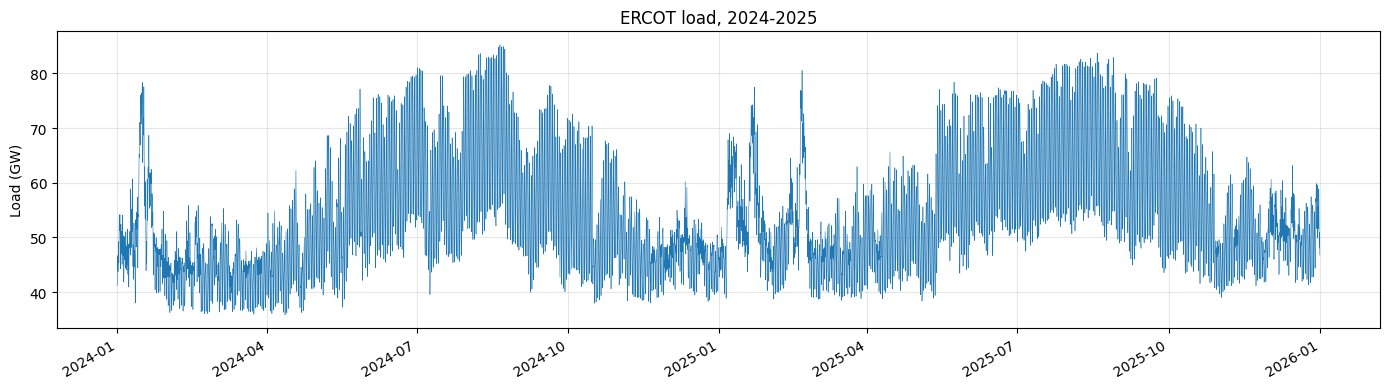

In [47]:
fig, ax = plt.subplots(figsize=(14, 4))
(df["ERCOT"] / 1000).plot(lw=0.4)
ax.set_ylabel("Load (GW)")
ax.set_xlabel("")
ax.set_title("ERCOT load, 2024-2025")
ax.grid(True, alpha=0.3)
plt.tight_layout()

Electricity consumption peaks in the summer at roughly 85 GW. Moderate winter peaks are also visible at 70 GW

2024-07-15 17:00:00


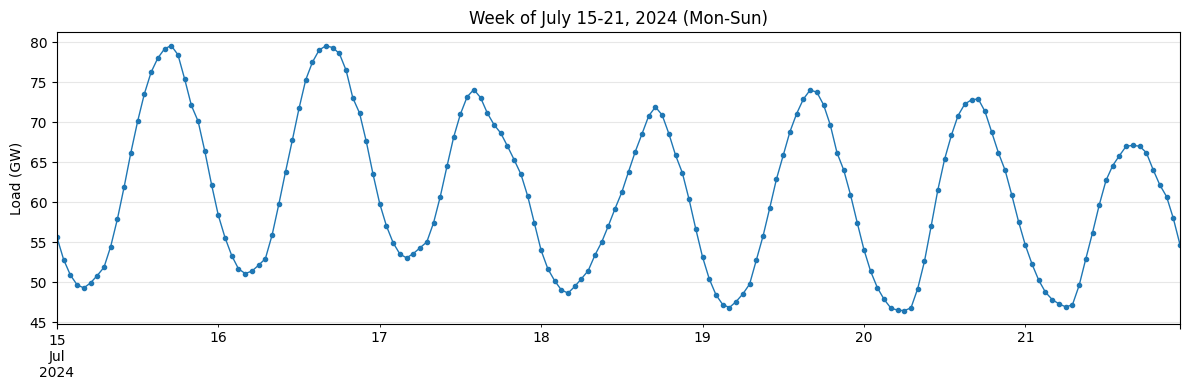

In [48]:
week = df.loc["2024-07-15":"2024-07-21", "ERCOT"] / 1000
print(week.idxmax()) # check time of peak consumption for 7/15

fig, ax = plt.subplots(figsize=(12, 4))
week.plot(marker=".", lw=1)
ax.set_ylabel("Load (GW)")
ax.set_xlabel("")
ax.set_title("Week of July 15-21, 2024 (Mon-Sun)")
ax.grid(True, alpha=0.3)
plt.tight_layout()

Summer loads peak between 4 PM and 5PM on weekdays at 75-80 GW

2024-01-22   2024-01-22 07:00:00
2024-01-23   2024-01-23 10:00:00
2024-01-24   2024-01-24 18:00:00
2024-01-25   2024-01-25 19:00:00
2024-01-26   2024-01-26 18:00:00
2024-01-27   2024-01-27 20:00:00
2024-01-28   2024-01-28 07:00:00
Name: ERCOT, dtype: datetime64[us]


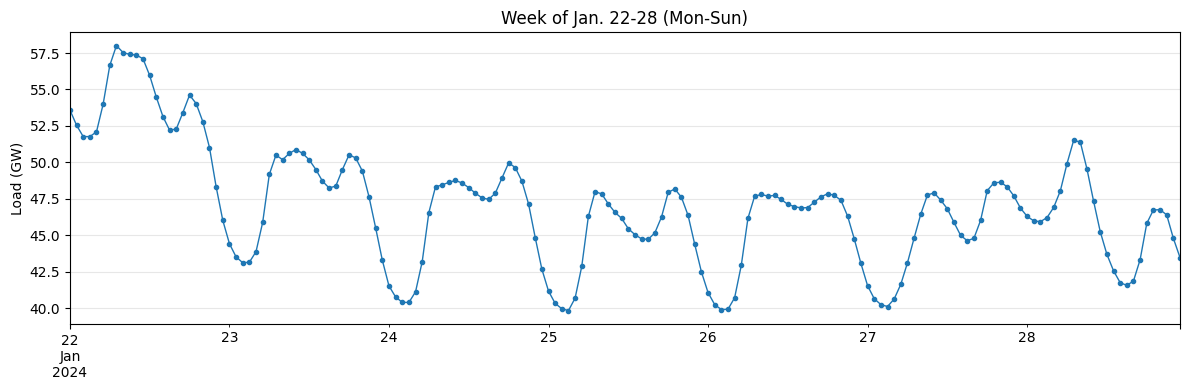

In [49]:
week = df.loc["2024-01-22":"2024-01-28", "ERCOT"] / 1000
print(week.groupby(week.index.date).idxmax()) # check times of peak consumption

fig, ax = plt.subplots(figsize=(12, 4))
week.plot(marker=".", lw=1)
ax.set_ylabel("Load (GW)")
ax.set_xlabel("")
ax.set_title("Week of Jan. 22-28 (Mon-Sun)")
ax.grid(True, alpha=0.3)
plt.tight_layout()

Winter loads peak twice, once around 7 to 8 AM and another around 6 to 7 PM on weekdays

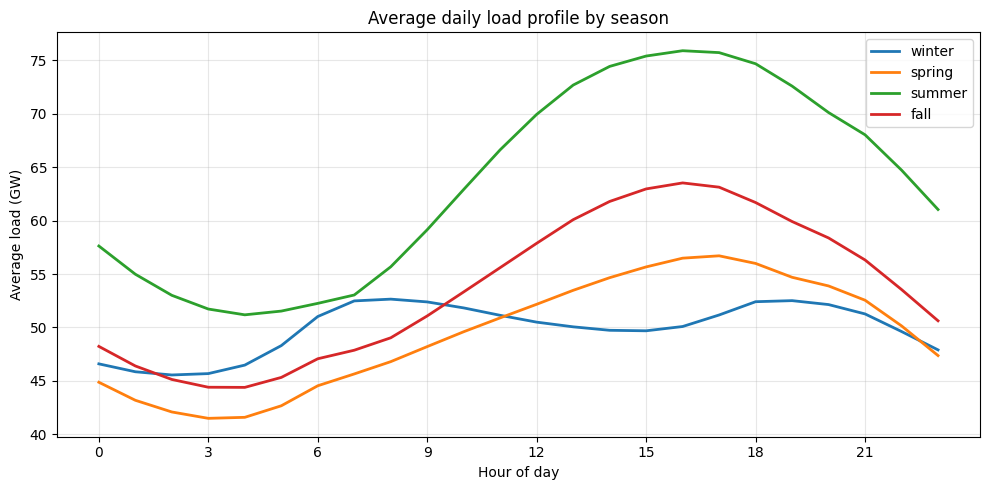

In [50]:
profile = (df.groupby(["season", "hour"])["ERCOT"].mean().unstack("season") / 1000)
profile = profile[["winter", "spring", "summer", "fall"]]

fig, ax = plt.subplots(figsize=(10, 5))
profile.plot(ax=ax, lw=2)
ax.set_xlabel("Hour of day")
ax.set_ylabel("Average load (GW)")
ax.set_title("Average daily load profile by season")
ax.set_xticks(range(0, 24, 3))
ax.grid(True, alpha=0.3)
ax.legend(title="")
plt.tight_layout()

Summer shows the highest load, with a peak between 12 and 7 PM. Winter is bimodal, having both morning and evening peaks. Spring and fall have peaks similar in shape to summer but with much lower loads.

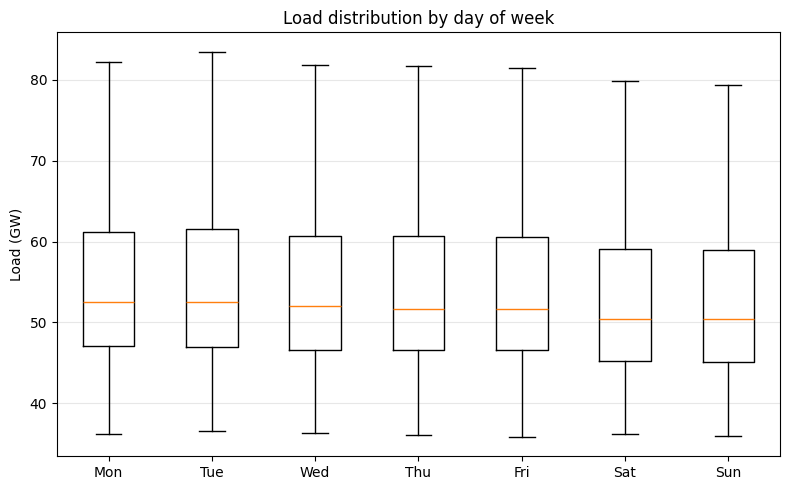

In [51]:
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
data_by_dow = [df.loc[df["dow"] == d, "ERCOT"].values / 1000 for d in range(7)]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(data_by_dow, showfliers=False)
ax.set_xticks(range(1, 8))
ax.set_xticklabels(dow_names)
ax.set_ylabel("Load (GW)")
ax.set_title("Load distribution by day of week")
ax.grid(True, alpha=0.3, axis="y")
plt.tight_layout()

Weekday loads are higher than on weekends

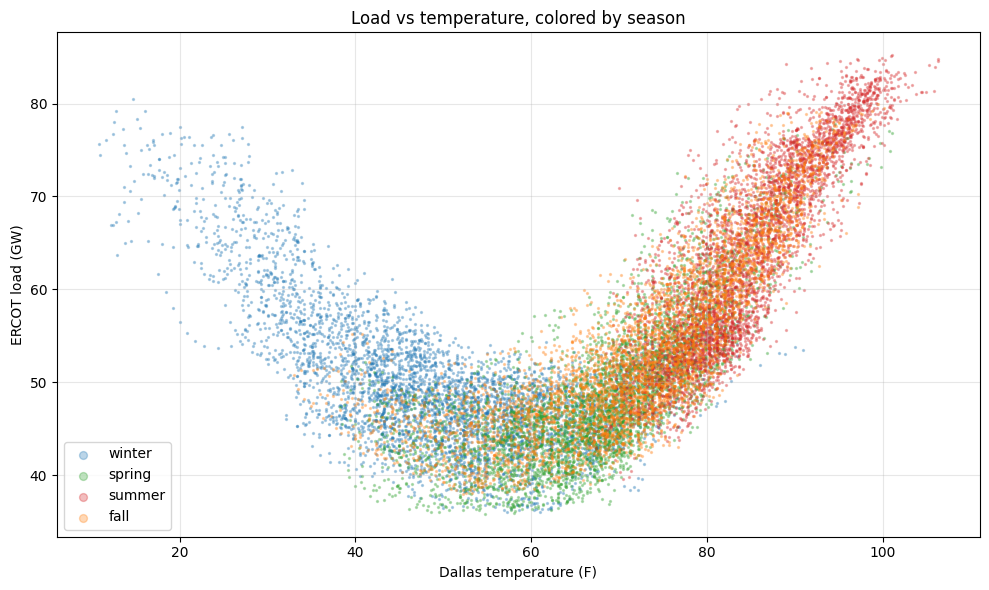

In [52]:
fig, ax = plt.subplots(figsize=(10, 6))
season_colors = {"winter": "C0", "spring": "C2", "summer": "C3", "fall": "C1"}

for s, c in season_colors.items():
    sub = df[df["season"] == s]
    ax.scatter(sub["dallas_temp_f"], sub["ERCOT"] / 1000,
               s=2, alpha=0.3, c=c, label=s)

ax.set_xlabel("Dallas temperature (F)")
ax.set_ylabel("ERCOT load (GW)")
ax.set_title("Load vs temperature, colored by season")
ax.legend(markerscale=4)
ax.grid(True, alpha=0.3)
plt.tight_layout()

Load peaks in winter and summer (in Dallas) when temperatures drop low (<40 degrees) and rise high (>90 degrees)

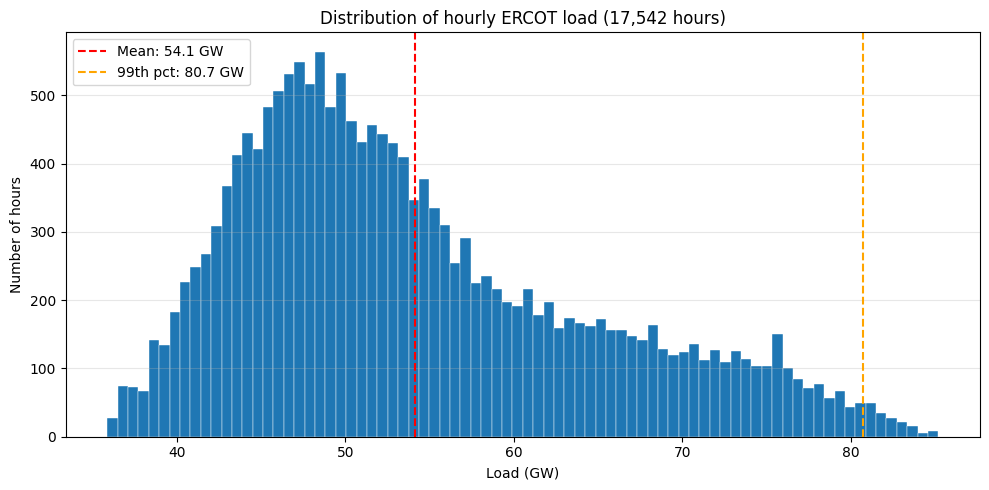

In [53]:
load_gw = df["ERCOT"] / 1000

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(load_gw, bins=80, edgecolor="white", linewidth=0.3)
ax.axvline(load_gw.mean(), color="red", linestyle="--",
           label=f"Mean: {load_gw.mean():.1f} GW")
ax.axvline(load_gw.quantile(0.99), color="orange", linestyle="--",
           label=f"99th pct: {load_gw.quantile(0.99):.1f} GW")
ax.set_xlabel("Load (GW)")
ax.set_ylabel("Number of hours")
ax.set_title(f"Distribution of hourly ERCOT load ({len(df):,} hours)")
ax.legend()
ax.grid(True, alpha=0.3, axis="y")
plt.tight_layout()

ERCOT has an average load of 54 GW, but importantly spikes up into the 70-80 range for hundreds of hours

                    dallas_temp_f  houston_temp_f  san_antonio_temp_f
dallas_temp_f               1.000           0.933               0.944
houston_temp_f              0.933           1.000               0.959
san_antonio_temp_f          0.944           0.959               1.000


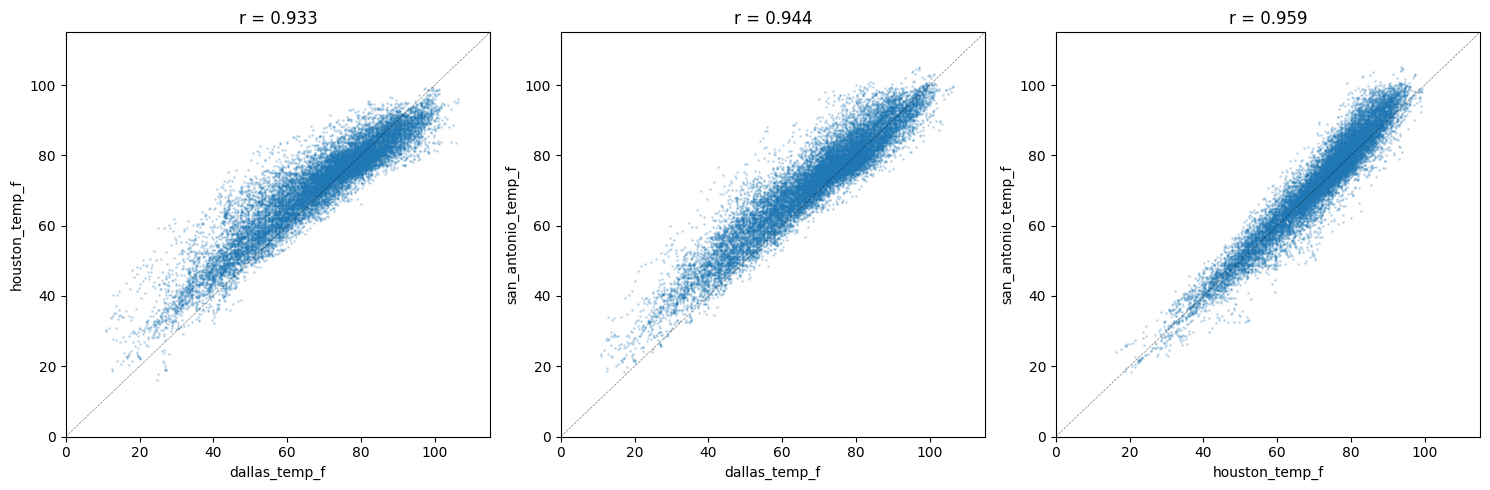

In [54]:
temp_cols = ["dallas_temp_f", "houston_temp_f", "san_antonio_temp_f"]
print(df[temp_cols].corr().round(3))

pairs = [("dallas_temp_f", "houston_temp_f"),
         ("dallas_temp_f", "san_antonio_temp_f"),
         ("houston_temp_f", "san_antonio_temp_f")]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (x, y) in zip(axes, pairs):
    ax.scatter(df[x], df[y], s=1, alpha=0.2)
    ax.plot([0, 115], [0, 115], "k--", lw=0.5, alpha=0.5)
    ax.set_xlabel(x); ax.set_ylabel(y)
    ax.set_title(f"r = {df[x].corr(df[y]):.3f}")
    ax.set_xlim(0, 115); ax.set_ylim(0, 115)

plt.tight_layout()

Three r values all >0.9 when comparing Dallas, Houston, and San Antonio to each other indicate that weather patterns are shared among the three cities. All three cannot be used together in linear regression without multicollinearity

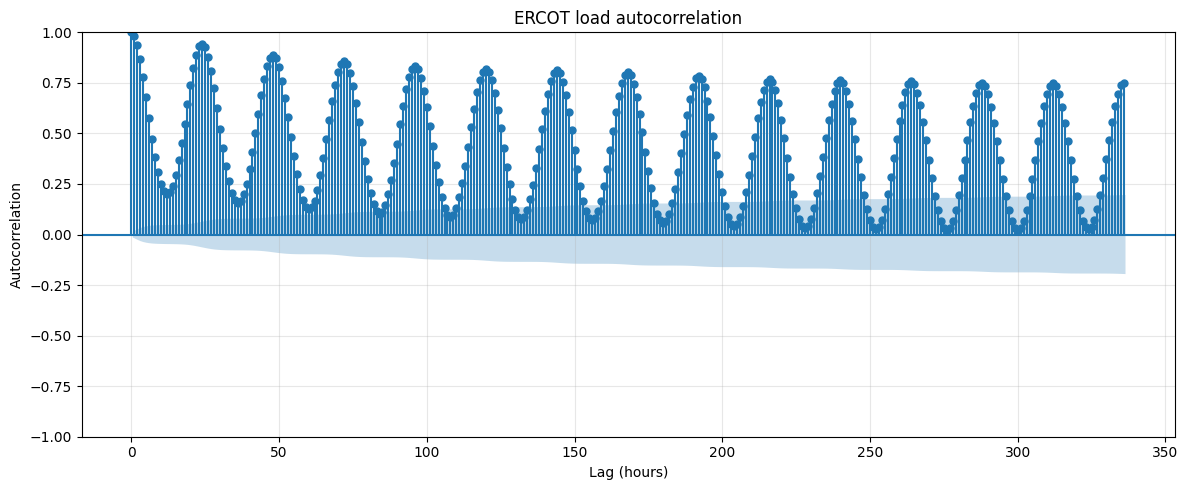

In [55]:
from statsmodels.graphics.tsaplots import plot_acf

fig, ax = plt.subplots(figsize=(12, 5))
plot_acf(df["ERCOT"], lags=24*14, ax=ax)
ax.set_xlabel("Lag (hours)")
ax.set_ylabel("Autocorrelation")
ax.set_title("ERCOT load autocorrelation")
ax.grid(True, alpha=0.3)
plt.tight_layout()

Spikes are consistent across 24 hour time gaps. Lag 24 and lag 168 (same hour but different week) have high autocorrelation

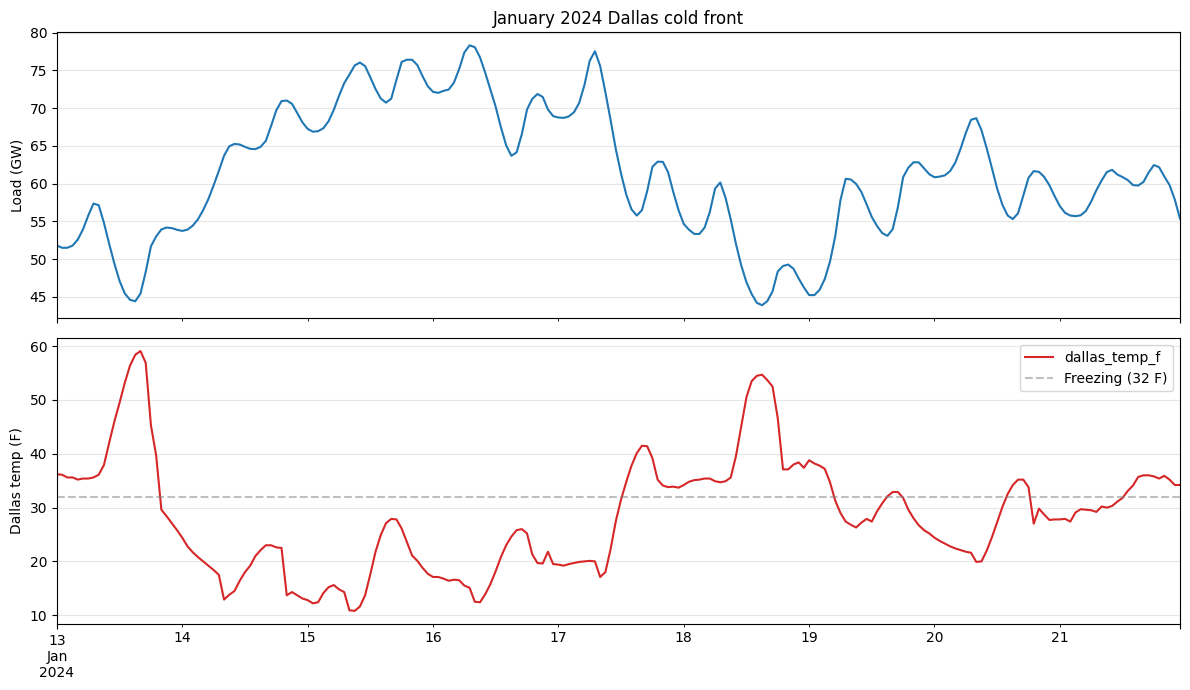

In [56]:
cold = df.loc["2024-01-13":"2024-01-21"]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

(cold["ERCOT"] / 1000).plot(ax=ax1, color="C0", lw=1.5)
ax1.set_ylabel("Load (GW)")
ax1.set_title("January 2024 Dallas cold front")
ax1.grid(True, alpha=0.3)

cold["dallas_temp_f"].plot(ax=ax2, color="C3", lw=1.5)
ax2.axhline(32, color="gray", ls="--",  alpha=0.5, label="Freezing (32 F)")
ax2.set_ylabel("Dallas temp (F)")
ax2.set_xlabel("")
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.tight_layout()

Severe Dallas cold front caused load to climb above 75 GW when winter peaks are typically 60. Unusual weather events have to be accounted for